# 2. Prior Success

> **Overview.** Only the LTUs tried on an output can show that its remaining error is noise (notebook 1). Can search
> draw parents by the share of each output's LTUs that help it, never stop giving new LTUs to any output, and stay near
> uniform parents where nothing tells the outputs apart?

**Setup.** Notebook 1's learner. Three problems, each with noise of std 0.1 or 1 on the outputs that read target LTUs:
- notebook 1's problem: 20 outputs, of which 2 read target LTUs and 18 are decoys (noise, or noisy linear); from 200k
  steps, every 100k steps one decoy becomes a target;
- 20 outputs that all read target LTUs, with no changes: here uniform parents are correct;
- 100 outputs, of which 10 read target LTUs and 90 are noisy linear decoys, with the same changes: many more outputs
  than new LTUs.

Each new LTU gets a parent output, drawn:
- uniformly (baseline: the current method);
- **by prior success** (proposed): in proportion to $(H_o + e_o + p) / (N_o + 2)$. $N_o$ counts the LTUs of output
  $o$, and $H_o$ those that help it now: removing such an LTU would raise $o$'s squared error by more than 3 standard
  errors. The explained fraction $e_o$ and the share $p$ of all LTUs that help their parent act as two pseudo-LTUs, so
  no output's weight is ever 0;
- by an oracle, in proportion to $L_o$, but only among the outputs that read target LTUs (reference).

5 seeds; 600k steps.

In [1]:
import os
from functools import partial
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
OUTPUT_FAN_IN = 4                    # target LTUs each learnable output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful
HELP_Z = 3.0                         # an LTU helps if its removal would raise its parent's error by this many standard
                                     # errors

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
DECAY = 1 - 1 / PERIOD               # factor by which the sums of the statistics decay at each step
UNIFORM, PRIOR_SUCCESS, ORACLE = range(3)   # how a new LTU's parent output is drawn
NOISE, NOISY_LINEAR = range(2)                         # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, outputs, N_ALL_TARGETS): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, outputs, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, outputs): each output's noise, by version


def make_target(key, kind, noise_std, n_outputs, n_learnable):
    # Version 0: the first n_learnable outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are noise
    # of std 1, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for every
    # output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES random inputs, with random
    # +-1 weights. Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with
    # noise of std noise_std (no change if there is no decoy).
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(n_outputs)[:, None] < n_learnable
    reads = jnp.pad(pick(out_key, (n_outputs, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (n_outputs, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (n_outputs, N_INPUTS), dtype=float)
              * pick(linear_key, (n_outputs, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind == NOISY_LINEAR))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoys = ~(out != 0).any(1)
        decoy = jax.random.categorical(decoy_key, jnp.where(decoys, 0.0, -1e9))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        out = jnp.where(decoys.any(), out.at[decoy].set(row), out)
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, target.noise_std.shape[1:]))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1], of which each output reads only its own LTUs.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (outputs, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (outputs, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (outputs,): each output's squared errors, summed with weights that decay by DECAY
    target_sum: jax.Array       # (outputs,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    weight_sum: jax.Array       # (): the weights of these sums, summed
    removal: jax.Array          # (N_LTUS,): the rise in its parent's squared error if it were removed, summed likewise
    removal_sq: jax.Array       # (N_LTUS,): the squares of these rises, summed likewise
    age: jax.Array              # (N_LTUS,): the steps since search added it


def init_net(key, n_outputs):
    # N_LTUS new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + 1)), 'output': jnp.zeros((n_outputs, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    zero, units = jnp.zeros(n_outputs), jnp.zeros(N_LTUS)
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((n_outputs, N_LTUS)),
              jnp.zeros((N_LTUS, N_INPUTS)), zero, zero, zero, jnp.zeros(()), units, units, units)
    return rewire(net, key, jnp.ones(N_LTUS, bool), jnp.zeros(n_outputs), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    n_outputs = net.shadow.shape[0]
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(n_outputs)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each output reading only
    # its own LTUs, and each LTU's shadow weight standing in for its weight to its parent in the backward pass while the
    # real one is smaller than 1 in magnitude. Returns the new network and each output's squared error on this sample,
    # before learning from it, which it also adds to loss_sum after the sums of the statistics decay by DECAY; adds the
    # targets and their squares to target_sum and target_sq_sum, 1 to weight_sum, dL/dz * x_i to each LTU's gradient
    # sums, and to `removal` (and its square to `removal_sq`) the rise in its parent's squared error if its part of the
    # prediction were removed. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.
    feeds = net.shadow != 0
    mask = jnp.concatenate([jnp.ones((len(feeds), N_INPUTS), bool), feeds, jnp.ones((len(feeds), 1), bool)], 1)

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where(feeds & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y))

    (_, (source, h, mean, residual)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * mask}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': source * mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    parent_residual = jnp.abs(net.shadow).T @ residual
    rise = (parent_residual - net.w['output'][:, N_INPUTS:-1].sum(0) * h) ** 2 - parent_residual ** 2
    squared = residual ** 2
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=DECAY * net.loss_sum + squared,
                        target_sum=DECAY * net.target_sum + y, target_sq_sum=DECAY * net.target_sq_sum + y ** 2,
                        weight_sum=DECAY * net.weight_sum + 1, removal=DECAY * net.removal + rise,
                        removal_sq=DECAY * net.removal_sq + rise ** 2, age=net.age + 1), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's squared weight to its parent, its only output: about the increase in its parent's squared error if it
    # were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def helps(net):
    # (N_LTUS,): whether the mean of the rises in its parent's squared error if it were removed, weighted as in their
    # sums, is more than HELP_Z standard errors: the standard deviation of the rises times sqrt(n2) / n, with n the sum
    # of the weights and n2 the sum of their squares.
    n = (1 - DECAY ** net.age) / (1 - DECAY)
    n2 = (1 - DECAY ** (2 * net.age)) / (1 - DECAY ** 2)
    mean = net.removal / jnp.maximum(n, 1)
    variance = jnp.maximum(net.removal_sq / jnp.maximum(n, 1) - mean ** 2, 0.0)
    return net.removal > HELP_Z * jnp.sqrt(variance * n2)


def parent_logits(net, rule, learnable):
    # Log-probabilities of each output being a new LTU's parent: uniform; in proportion to (H + e + p) / (N + 2), with N
    # its LTUs, H those that help it, e = (V - L) / V its explained fraction, L its mean squared error and V its
    # targets' variance, weighted as in their sums, e 0 if negative, and p the share of all LTUs that help their parent
    # (PRIOR_SUCCESS); or in proportion to L, among only the outputs reading target LTUs (ORACLE). Uniform if all are 0.
    loss = net.loss_sum / net.weight_sum
    variance = net.target_sq_sum / net.weight_sum - (net.target_sum / net.weight_sum) ** 2
    explained = jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)
    ltus = jnp.abs(net.shadow)
    helpers = ltus @ helps(net)
    weight = jnp.select([rule == PRIOR_SUCCESS, rule == ORACLE],
                        [(helpers + explained + helpers.sum() / N_LTUS) / (ltus.sum(1) + 2), loss * learnable],
                        jnp.ones_like(loss))
    return jnp.log(jnp.where(weight.sum() > 0, weight, 1.0))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps search replaces the REPLACED
    # least useful LTUs by new ones with parents drawn by `rule`.
    # Returns, for each window, the mean squared error over the outputs then reading target LTUs.

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        new = rewire(net, wire_key, weakest, parent_logits(net, rule, learnable), True, True)
        new = new._replace(removal=jnp.where(weakest, 0.0, new.removal), removal_sq=jnp.where(weakest, 0.0, new.removal_sq),
                           age=jnp.where(weakest, 0, new.age))
        net = pick((index + 1) * WINDOW % PERIOD == 0, new, net)
        squared = squared.mean(0)
        return net, (squared * learnable).sum() / learnable.sum()

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(n_outputs, configs):
    # Each (learnable outputs, decoy kind, noise std, rule) of configs on N_SEEDS seeds, vmapped together, with n_outputs
    # outputs; seed s gives every run the same target LTUs and inputs. Returns {config: the RMSE over the outputs then
    # reading target LTUs, (seed, window)}.
    n_learnable, kind, noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                         for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(partial(make_target, n_outputs=n_outputs))(keys(2), kind, noise, n_learnable=n_learnable)
    nets = jax.vmap(partial(init_net, n_outputs=n_outputs))(keys(0))
    mse = jax.jit(jax.vmap(train))(nets, keys(1), targets, rule)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
PROBLEMS = [((20, 2, NOISE), '20 outputs, 2 learnable, noise decoys'),       # (outputs, learnable outputs, decoys)
            ((20, 2, NOISY_LINEAR), '20 outputs, 2 learnable, noisy linear decoys'),
            ((20, 20, NOISE), '20 outputs, all learnable'),
            ((100, 10, NOISY_LINEAR), '100 outputs, 10 learnable, noisy linear decoys')]
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red'),
         ('prior success', 'proposed', PRIOR_SUCCESS, 'tab:blue'),
         ('oracle', 'reference: error, among only the outputs reading target LTUs', ORACLE, 'tab:gray')]
started = perf_counter()
results = {}
for n_outputs in sorted({problem[0] for problem, _ in PROBLEMS}):
    configs = [(problem[1:], noise, rule) for problem, _ in PROBLEMS if problem[0] == n_outputs
               for noise in NOISE_STDS for _, _, rule, _ in RULES]
    runs = run(n_outputs, [(*p, noise, rule) for p, noise, rule in configs])
    for (p, noise, rule), rmse in zip(configs, runs.values()):
        results[((n_outputs, *p), noise, rule)] = rmse
print(f'{len(PROBLEMS) * len(NOISE_STDS) * len(RULES) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

120 runs in 113s


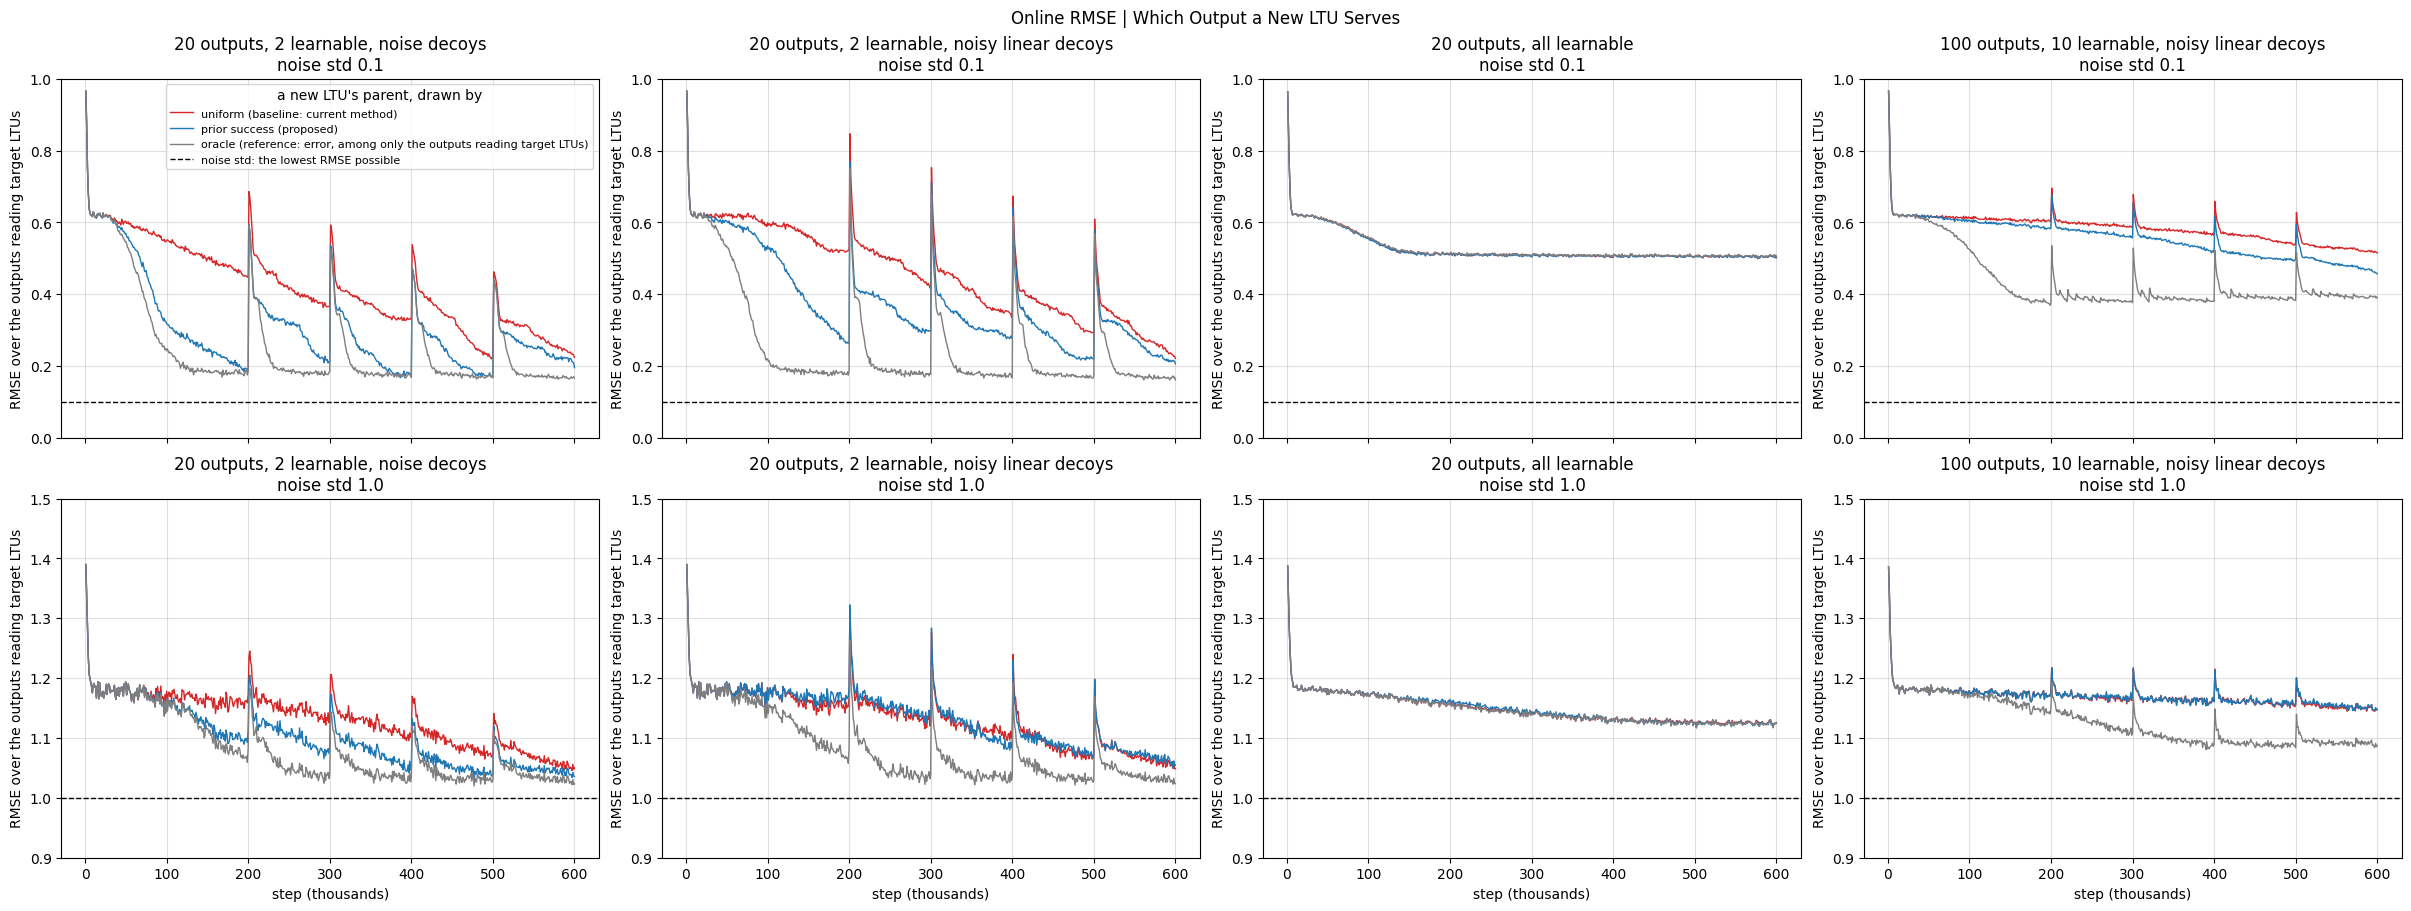

20 outputs, 2 learnable, noise decoys, noise std 0.1, RMSE averaged over the run: uniform 0.422, prior success 0.309, oracle 0.258
20 outputs, 2 learnable, noise decoys, noise std 1.0, RMSE averaged over the run: uniform 1.133, prior success 1.101, oracle 1.081
20 outputs, 2 learnable, noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.462, prior success 0.377, oracle 0.258
20 outputs, 2 learnable, noisy linear decoys, noise std 1.0, RMSE averaged over the run: uniform 1.131, prior success 1.135, oracle 1.081
20 outputs, all learnable, noise std 0.1, RMSE averaged over the run: uniform 0.527, prior success 0.526, oracle 0.528
20 outputs, all learnable, noise std 1.0, RMSE averaged over the run: uniform 1.148, prior success 1.148, oracle 1.147
100 outputs, 10 learnable, noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.584, prior success 0.556, oracle 0.435
100 outputs, 10 learnable, noisy linear decoys, noise std 1.0, RMSE averaged over th

In [7]:
YLIMS = [(0, 1.0), (0.9, 1.5)]   # zoomed at noise std 1, where the gaps shrink near the floor
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
fig, axes = plt.subplots(2, len(PROBLEMS), figsize=(24, 9), sharex=True, layout='constrained')
for column, (problem, title) in enumerate(PROBLEMS):
    for row, (noise, ylim) in enumerate(zip(NOISE_STDS, YLIMS)):
        ax = axes[row, column]
        for name, role, rule, color in RULES:
            ax.plot(STEPS / 1000, results[(problem, noise, rule)].mean(0), color=color, lw=1, label=f'{name} ({role})')
        ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
        ax.set(title=f'{title}\nnoise std {noise}', ylim=ylim, ylabel='RMSE over the outputs reading target LTUs')
        ax.grid(alpha=0.4)
for ax in axes[1]:
    ax.set(xlabel='step (thousands)')
axes[0, 0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('Online RMSE | Which Output a New LTU Serves')
plt.show()

for problem, title in PROBLEMS:
    for noise in NOISE_STDS:
        print(f'{title}, noise std {noise}, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(problem, noise, rule)].mean():.3f}' for name, _, rule, _ in RULES))

## Results

**With noise decoys**, prior success comes close to the oracle: RMSE averaged over the run 0.309 against 0.258 at
noise std 0.1 (uniform parents 0.422), and 1.101 against 1.081 at noise std 1 (uniform parents 1.133). The pseudo-LTU
$p$ gives every noise decoy a few new LTUs, and this costs part of the gap.

**With noisy linear decoys**, it does better than uniform parents at noise std 0.1 (0.377 against 0.462), where error
times explained fraction did worse (notebook 1). At noise std 1, it is level with uniform parents (1.135 against
1.131). There, a noisy linear decoy has a larger explained fraction than a learnable output (0.5 against about 0.3), so
the prior points the wrong way, and the LTUs tried only cancel it.

**When all outputs are learnable**, all the rules are equal (0.526 to 0.528, and 1.147 to 1.148): prior success loses
nothing where nothing tells the outputs apart. The RMSE stays high because each output needs LTUs of its own, and 32
LTUs are too few for 20 outputs.

**With 100 outputs**, it does a little better than uniform parents at noise std 0.1 (0.556 against 0.584) and as well
at noise std 1 (1.169 against 1.168), but it stays far from the oracle (0.435 and 1.126). Most of the 90 decoys have
few LTUs or none, so the prior decides most parents.

## Details

**Two pseudo-LTUs.** An output with no LTUs gets the weight $(e_o + p) / 2$. Pure noise has an explained fraction of
0, and a new LTU starts from its parent's linear weights, so it cannot build on an output that the linear learner does
not explain at all. But some learnable outputs have no linear part, so $p$ keeps the weight of every output above 0.
One pseudo-LTU each is the usual weight of a prior.

**No memory.** The weight uses only the LTUs that an output has now. Search replaces LTUs that do not help, so the
failures of an output leave with them. Thus, an output that becomes learnable later, for example a decoy that becomes
a target, gets new LTUs again with no decay rate. Counting each LTU once instead, as a win at the first step where it
helps, did worse in pilot runs (0.41 to 0.43 with noisy linear decoys at noise std 0.1, against 0.377 here): checked at
every step, the test passes by chance at some step much more often than at one step.

**The help test.** Removing an LTU from its parent's prediction changes the parent's squared error at each step.
Search compares the weighted mean of this rise with its standard error. A useless LTU's weight moves at random, and the
test measures the rise against this randomness, so it needs no scale of its own. In pilot runs from 1 to 10 standard
errors, the RMSE changed by at most 0.04: a lower threshold helps with noisy linear decoys, and a higher one with noise
decoys.

**Statistics.** Every statistic is a sum whose weights decay by a factor of $1 - 1/10\text{k}$ at each step, so search
can draw parents at any step. Only the replacement of LTUs still happens every 10k steps.

**Scale.** Each quantity of the rule belongs to one output or one LTU, except $p$, a share over all LTUs. Its two
numbers are common defaults. Thus, the rule does not depend on the number of LTUs or outputs.

The rest is as in notebook 1.